# EDA: BTC/USDT de Binance

El análisis utiliza un solo símbolo y una sola fuente: BTC/USDT spot de Binance, velas de una hora. Las particiones temporales se leen de `configs/project.toml`.

**Política de huecos:** el dataset descargado se conserva intacto. Para un dataset derivado, se completan únicamente los huecos internos de hasta cinco horas usando causalmente el último cierre conocido como OHLC y volumen cero. Las velas sintéticas quedan marcadas con `is_interpolated=True`. No se inventan las seis horas iniciales porque no existe un cierre previo. El EDA compara datos observados y derivados y advierte dónde la imputación puede distorsionar estadísticas.

**Convención temporal:** los indicadores técnicos se desplazan una vela para que las observaciones usadas al tomar una decisión no incluyan el cierre de esa vela. No se usan fechas futuras para construir observaciones.

In [ ]:
from pathlib import Path
import sys
import tomllib

import matplotlib.pyplot as plt
import numpy as np
import pandas as pdp

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import importlib
import src.data as data_module
importlib.reload(data_module)
from src.data import interpolate_short_gaps, load_ohlcv, load_split_config, split_by_dates

CONFIG_PATH = ROOT / "configs" / "project.toml"
with CONFIG_PATH.open("rb") as f:
    config = tomllib.load(f)
DATA_PATH = ROOT / config["dataset"]["path"]
SEED = config["project"]["seed"]
data, quality = load_ohlcv(DATA_PATH, config["dataset"]["expected_frequency"])
PREPROCESSING = config["preprocessing"]
data_filled = interpolate_short_gaps(
    data,
    expected_frequency=config["dataset"]["expected_frequency"],
    max_gap_hours=PREPROCESSING["max_gap_hours"],
)
print(f"Dataset: {DATA_PATH}; símbolo: {config['dataset']['symbols'][0]}; exchange: {config['dataset']['exchange']}; seed: {SEED}")
pd.Series(quality.to_dict(), name="calidad")

Dataset: /Volumes/ExternalMacMini/MIA/RL/ProyectoFinal_RL/data/binance-BTCUSDT-1h.pkl; símbolo: BTC/USDT; exchange: binance; seed: 42


source_rows                                                                 59122
clean_rows                                                                  59122
start                                                   2020-01-01T06:00:00+00:00
end                                                     2026-09-30T23:00:00+00:00
input_was_chronological                                                      True
duplicate_rows                                                                  0
rows_with_nulls                                                                 0
null_values_by_column           {'timestamp': 0, 'open': 0, 'high': 0, 'low': ...
missing_timestamps                                                             32
missing_timestamp_examples      [dataset: 2020-02-09T02:00:00+00:00, dataset: ...
rows_by_series                                                 {'dataset': 59122}
missing_timestamps_by_series                                      {'dataset': 32}
Name: calidad, d

### calidad del dataset

Se puede identificar que no existen valores nulos ni valores duplicados. Lo que si existen son valores faltantes,  que es diferente a un valor nulo, el valor nulo es cuando la observación existe pero una de sus características es nula, en este caso no se encuentran las observaciones esperadas para uno valores de timestamp.

32 valores faltantes de 59122 observaciones no es un porcentaje alto,  por lo tanto lo que importa es donde se encuentran y cuando dura cada espacio faltante. 

## Validación de valores faltantes



In [11]:
frequency = pd.Timedelta(config["dataset"]["expected_frequency"])
period_start = pd.Timestamp(config["dataset"]["since"], tz="UTC")
period_end = pd.Timestamp(config["dataset"]["until_exclusive"], tz="UTC")
expected_timestamps = pd.date_range(
    start=period_start,
    end=period_end,
    freq=config["dataset"]["expected_frequency"],
    inclusive="left",
)
observed_timestamps = pd.DatetimeIndex(data["timestamp"])
missing_timestamps = expected_timestamps.difference(observed_timestamps)
missing_timestamp_table = pd.DataFrame({"missing_timestamp_utc": missing_timestamps})

print(f"Velas esperadas: {len(expected_timestamps):,}")
print(f"Velas observadas: {len(observed_timestamps):,}")
print(f"Timestamps faltantes: {len(missing_timestamps):,} ({len(missing_timestamps) / len(expected_timestamps):.5%} del calendario esperado)")
with pd.option_context("display.max_rows", None, "display.max_columns", None):
    display(missing_timestamp_table)

Velas esperadas: 59,160
Velas observadas: 59,122
Timestamps faltantes: 38 (0.06423% del calendario esperado)


,missing_timestamp_utc
0,2020-01-01 00:00:00+00:00
1,2020-01-01 01:00:00+00:00
2,2020-01-01 02:00:00+00:00
3,2020-01-01 03:00:00+00:00
4,2020-01-01 04:00:00+00:00
5,2020-01-01 05:00:00+00:00
6,2020-02-09 02:00:00+00:00
7,2020-02-19 12:00:00+00:00
8,2020-02-19 13:00:00+00:00
9,2020-02-19 14:00:00+00:00


### timestamps ausentes

Con este análisis identificamos 6 valores que deben ir al inicio del dataset y como no afectan la continuidad del mismo no consideramos necesario hacer ninguna interpolación de estos valorse. 

Existen algunos huecos importantes,  lo más importante es que los valores faltantes no se encuentra en los períodos más recientes, o sea 2025 y 2026 lo cual permite que los dataset de validación y prueba esten completos y puedan ser utilizados tal y como están. 

Para los valores faltantes, al ser tan pocos, decidimos interporlar,  esto debido a que al ser poco no afectarán de forma dramatica el proceso pero si mantendremos la continuidad de la información. 

In [12]:
if missing_timestamp_table.empty:
    gap_summary = pd.DataFrame(
        columns=[
            "gap_start_utc", "gap_end_utc", "missing_hours",
            "previous_close", "next_close", "return_across_gap",
        ]
    )
else:
    missing_timestamp_table["gap_id"] = (
        missing_timestamp_table["missing_timestamp_utc"].diff().ne(frequency).cumsum()
    )
    gap_summary = missing_timestamp_table.groupby("gap_id").agg(
        gap_start_utc=("missing_timestamp_utc", "min"),
        gap_end_utc=("missing_timestamp_utc", "max"),
        missing_hours=("missing_timestamp_utc", "size"),
    )
    observed_close = data.set_index("timestamp")["close"]
    gap_summary["previous_timestamp_utc"] = gap_summary["gap_start_utc"] - frequency
    gap_summary["next_timestamp_utc"] = gap_summary["gap_end_utc"] + frequency
    gap_summary["previous_close"] = gap_summary["previous_timestamp_utc"].map(observed_close)
    gap_summary["next_close"] = gap_summary["next_timestamp_utc"].map(observed_close)
    gap_summary["return_across_gap"] = (
        gap_summary["next_close"] / gap_summary["previous_close"] - 1
    )
    gap_summary = gap_summary.reset_index(drop=True)

print(f"Bloques de huecos: {len(gap_summary):,}")
if not gap_summary.empty:
    print("Duración de cada hueco (horas faltantes):")
    display(gap_summary["missing_hours"].value_counts().sort_index().rename_axis("horas_faltantes").rename("cantidad_de_bloques").to_frame())
    print("Detalle de huecos y movimiento observado entre sus extremos:")
    with pd.option_context("display.max_rows", None, "display.max_columns", None):
        display(gap_summary)
    print("Huecos más largos:")
    display(gap_summary.nlargest(10, "missing_hours"))

Bloques de huecos: 16
Duración de cada hueco (horas faltantes):


,cantidad_de_bloques
horas_faltantes,
1,7
2,3
3,2
4,2
5,1
6,1


Detalle de huecos y movimiento observado entre sus extremos:


,gap_start_utc,gap_end_utc,missing_hours,previous_timestamp_utc,next_timestamp_utc,previous_close,next_close,return_across_gap
0,2020-01-01 00:00:00+00:00,2020-01-01 05:00:00+00:00,6,2019-12-31 23:00:00+00:00,2020-01-01 06:00:00+00:00,NaN,7225.62,NaN
1,2020-02-09 02:00:00+00:00,2020-02-09 02:00:00+00:00,1,2020-02-09 01:00:00+00:00,2020-02-09 03:00:00+00:00,9938.90,10052.63,0.011443
2,2020-02-19 12:00:00+00:00,2020-02-19 16:00:00+00:00,5,2020-02-19 11:00:00+00:00,2020-02-19 17:00:00+00:00,10148.93,10158.94,0.000986
3,2020-03-04 10:00:00+00:00,2020-03-04 10:00:00+00:00,1,2020-03-04 09:00:00+00:00,2020-03-04 11:00:00+00:00,8795.06,8717.12,-0.008862
4,2020-04-25 02:00:00+00:00,2020-04-25 03:00:00+00:00,2,2020-04-25 01:00:00+00:00,2020-04-25 04:00:00+00:00,7480.78,7518.42,0.005032
5,2020-06-28 02:00:00+00:00,2020-06-28 04:00:00+00:00,3,2020-06-28 01:00:00+00:00,2020-06-28 05:00:00+00:00,8971.80,8961.59,-0.001138
6,2020-11-30 06:00:00+00:00,2020-11-30 06:00:00+00:00,1,2020-11-30 05:00:00+00:00,2020-11-30 07:00:00+00:00,18520.47,18623.00,0.005536
7,2020-12-21 14:00:00+00:00,2020-12-21 17:00:00+00:00,4,2020-12-21 13:00:00+00:00,2020-12-21 18:00:00+00:00,22681.32,22813.66,0.005835
8,2020-12-25 02:00:00+00:00,2020-12-25 02:00:00+00:00,1,2020-12-25 01:00:00+00:00,2020-12-25 03:00:00+00:00,23597.21,23481.21,-0.004916
9,2021-02-11 04:00:00+00:00,2021-02-11 04:00:00+00:00,1,2021-02-11 03:00:00+00:00,2021-02-11 05:00:00+00:00,44582.07,44641.72,0.001338


Huecos más largos:


,gap_start_utc,gap_end_utc,missing_hours,previous_timestamp_utc,next_timestamp_utc,previous_close,next_close,return_across_gap
0,2020-01-01 00:00:00+00:00,2020-01-01 05:00:00+00:00,6,2019-12-31 23:00:00+00:00,2020-01-01 06:00:00+00:00,NaN,7225.62,NaN
2,2020-02-19 12:00:00+00:00,2020-02-19 16:00:00+00:00,5,2020-02-19 11:00:00+00:00,2020-02-19 17:00:00+00:00,10148.93,10158.94,0.000986
7,2020-12-21 14:00:00+00:00,2020-12-21 17:00:00+00:00,4,2020-12-21 13:00:00+00:00,2020-12-21 18:00:00+00:00,22681.32,22813.66,0.005835
13,2021-08-13 02:00:00+00:00,2021-08-13 05:00:00+00:00,4,2021-08-13 01:00:00+00:00,2021-08-13 06:00:00+00:00,44847.26,45833.34,0.021988
5,2020-06-28 02:00:00+00:00,2020-06-28 04:00:00+00:00,3,2020-06-28 01:00:00+00:00,2020-06-28 05:00:00+00:00,8971.80,8961.59,-0.001138
12,2021-04-25 05:00:00+00:00,2021-04-25 07:00:00+00:00,3,2021-04-25 04:00:00+00:00,2021-04-25 08:00:00+00:00,49683.94,50086.13,0.008095
4,2020-04-25 02:00:00+00:00,2020-04-25 03:00:00+00:00,2,2020-04-25 01:00:00+00:00,2020-04-25 04:00:00+00:00,7480.78,7518.42,0.005032
11,2021-04-20 02:00:00+00:00,2021-04-20 03:00:00+00:00,2,2021-04-20 01:00:00+00:00,2021-04-20 04:00:00+00:00,54764.12,55258.63,0.009030
14,2021-09-29 07:00:00+00:00,2021-09-29 08:00:00+00:00,2,2021-09-29 06:00:00+00:00,2021-09-29 09:00:00+00:00,42450.25,42252.57,-0.004657
1,2020-02-09 02:00:00+00:00,2020-02-09 02:00:00+00:00,1,2020-02-09 01:00:00+00:00,2020-02-09 03:00:00+00:00,9938.90,10052.63,0.011443


## Acá realizamos la interpolación

Se completan únicamente timestamps internos faltantes con un hueco de hasta cinco horas. 

Velas sintéticas internas: 32
Ausencias iniciales no imputadas: 6
Filas observadas: 59,122; filas en dataset derivado: 59,154


,timestamp,open,high,low,close,volume,is_interpolated
932,2020-02-09 02:00:00+00:00,9938.90,9938.90,9938.90,9938.90,0.0,True
1182,2020-02-19 12:00:00+00:00,10148.93,10148.93,10148.93,10148.93,0.0,True
1183,2020-02-19 13:00:00+00:00,10148.93,10148.93,10148.93,10148.93,0.0,True
1184,2020-02-19 14:00:00+00:00,10148.93,10148.93,10148.93,10148.93,0.0,True
1185,2020-02-19 15:00:00+00:00,10148.93,10148.93,10148.93,10148.93,0.0,True
1186,2020-02-19 16:00:00+00:00,10148.93,10148.93,10148.93,10148.93,0.0,True
1516,2020-03-04 10:00:00+00:00,8795.06,8795.06,8795.06,8795.06,0.0,True
2756,2020-04-25 02:00:00+00:00,7480.78,7480.78,7480.78,7480.78,0.0,True
2757,2020-04-25 03:00:00+00:00,7480.78,7480.78,7480.78,7480.78,0.0,True
4292,2020-06-28 02:00:00+00:00,8971.80,8971.80,8971.80,8971.80,0.0,True


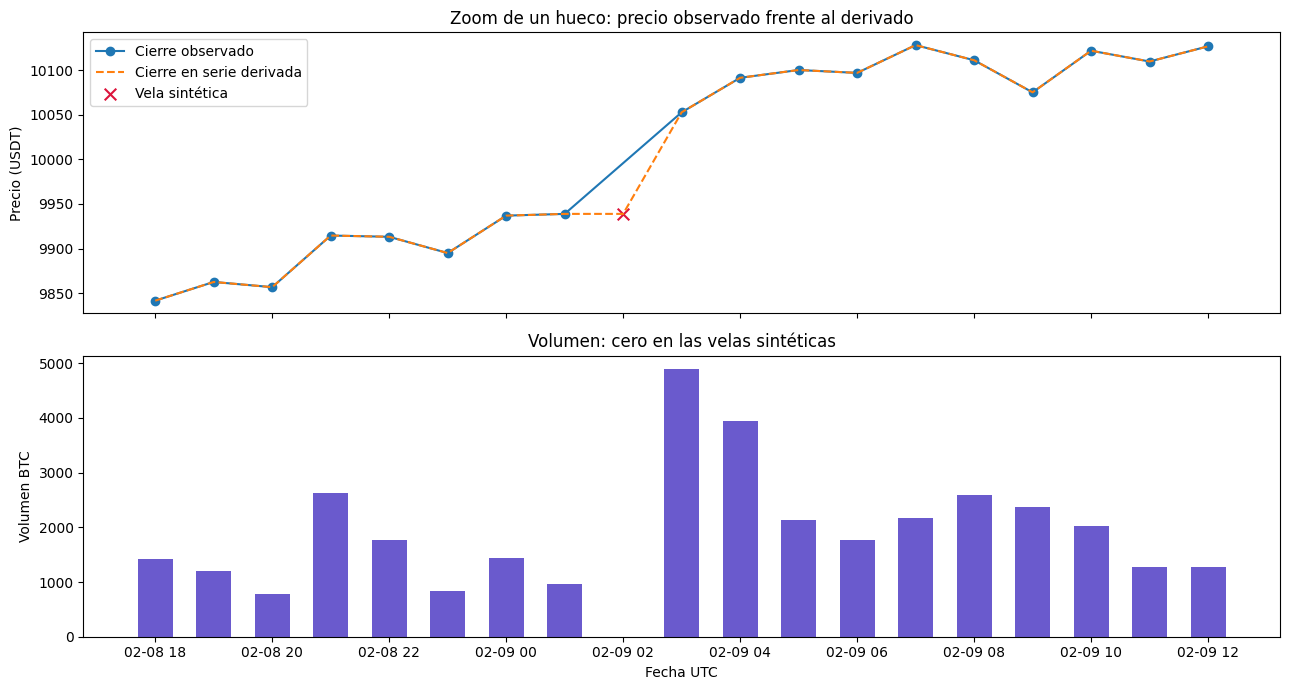

In [13]:
synthetic = data_filled["is_interpolated"]
initial_missing_count = int((missing_timestamps < data["timestamp"].min()).sum())
print(f"Velas sintéticas internas: {int(synthetic.sum()):,}")
print(f"Ausencias iniciales no imputadas: {initial_missing_count:,}")
print(f"Filas observadas: {len(data):,}; filas en dataset derivado: {len(data_filled):,}")
display(data_filled.loc[synthetic, ["timestamp", "open", "high", "low", "close", "volume", "is_interpolated"]].head(10))

first_gap = data_filled.loc[synthetic, "timestamp"].iloc[0]
window_start = first_gap - 8 * frequency
window_end = first_gap + 10 * frequency
observed_window = data.loc[data["timestamp"].between(window_start, window_end)]
filled_window = data_filled.loc[data_filled["timestamp"].between(window_start, window_end)]
fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True)
axes[0].plot(observed_window["timestamp"], observed_window["close"], marker="o", label="Cierre observado")
axes[0].plot(filled_window["timestamp"], filled_window["close"], linestyle="--", label="Cierre en serie derivada")
axes[0].scatter(filled_window.loc[filled_window["is_interpolated"], "timestamp"], filled_window.loc[filled_window["is_interpolated"], "close"], color="crimson", marker="x", s=70, label="Vela sintética")
axes[0].set_ylabel("Precio (USDT)")
axes[0].set_title("Zoom de un hueco: precio observado frente al derivado")
axes[0].legend()
axes[1].bar(filled_window["timestamp"], filled_window["volume"], width=0.025, color="slateblue")
axes[1].set(title="Volumen: cero en las velas sintéticas", ylabel="Volumen BTC", xlabel="Fecha UTC")
plt.tight_layout()
plt.show()

### Decisión de Interpolación

Dada su baja incidencia y con el objetivo de conservar la regularidad temporal requerida para la construcción de ventanas de entrenamiento, se decidió completar las observaciones faltantes mediante el método Forward Fill (ffill) en lugar de unsar una interpolación lineal. Este procedimiento asigna a cada observación ausente el último valor conocido, evitando utilizar información correspondiente a instantes posteriores al dato que se está reconstruyendo. Esta característica resulta relevante en el contexto de modelos predictivos de series temporales, ya que reduce el riesgo de introducir información futura durante el preprocesamiento.

## Se agregan los indicadores para el análisis de los datos

* Return: Cambio relativo de precio de una hora a la anterior. (Lo usaremos para interpretación de la información)
* log_return: Se recomienda calcularlo para utilizarlo en calculos estadísticos posteriores
* volatility_24: Es la desviación estandar de los datos de las últimas 24 horas,  si es alta dice que el retorno no es estable. 24 horas contienen 24 observaciones por lo tanto ya es una ventana de tiempo razonable para este análisis
* sma_24: Promedio del valor en los últimas 24 horas
* sma_168: Promedio de las últimas 168 horas. 168 horas corresponden a una semana, por lo tanto es otra ventana interesante de analizar. 
* dist_sma_24: La distancia nos iondica que tan lejos está por arriba o por abajo el precio de la media del período que en este caso son 24 horas
* dist_sma_168

Las medidas de distancia estandarizan los datos, ahora la información que va a recibir el modelo no son valores absolutos que podrían no indicar nada por si solo, en cambio la distancia frente a la media es independiente del valor e indica como está con relacón a su sma. 

* rsi_14: Medica del momentum, se toman 14 horas como una ventana razonable para este calculo. 
* Se mueven los indicadores una observación,  técnica utilizada para evitar look-ahead bias.
* drawdown: % de desfase frente al precio máximo historico. 


In [14]:
data = data.sort_values("timestamp").reset_index(drop=True)
adjacent_hour = data["timestamp"].diff().eq(frequency)
data["return"] = data["close"].pct_change().where(adjacent_hour)
data["log_return"] = np.log(data["close"]).diff().where(adjacent_hour)
data["volatility_24"] = data["log_return"].rolling(24, min_periods=24).std()
data["sma_24"] = data["close"].rolling(24, min_periods=24).mean()
data["sma_168"] = data["close"].rolling(168, min_periods=168).mean()
data["dist_sma_24"] = data["close"] / data["sma_24"] - 1
data["dist_sma_168"] = data["close"] / data["sma_168"] - 1
delta = data["close"].diff()
gain = delta.clip(lower=0).rolling(14, min_periods=14).mean()
loss = -delta.clip(upper=0).rolling(14, min_periods=14).mean()
relative_strength = gain / loss.replace(0, np.nan)
data["rsi_14"] = 100 - 100 / (1 + relative_strength)
data.loc[(loss == 0) & (gain > 0), "rsi_14"] = 100
data.loc[(loss == 0) & (gain == 0), "rsi_14"] = 50
indicator_columns = ["sma_24", "sma_168", "dist_sma_24", "dist_sma_168", "volatility_24", "rsi_14"]
data[indicator_columns] = data[indicator_columns].shift(1)
data["drawdown"] = data["close"] / data["close"].cummax() - 1
data.head()

,timestamp,open,high,low,close,volume,return,log_return,volatility_24,sma_24,sma_168,dist_sma_24,dist_sma_168,rsi_14,drawdown
0,2020-01-01 06:00:00+00:00,7224.24,7236.27,7221.51,7225.62,621.467023,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000
1,2020-01-01 07:00:00+00:00,7225.88,7232.94,7199.11,7209.83,627.344854,-0.002185,-0.002188,NaN,NaN,NaN,NaN,NaN,NaN,-0.002185
2,2020-01-01 08:00:00+00:00,7209.83,7210.00,7180.00,7200.64,915.545974,-0.001275,-0.001275,NaN,NaN,NaN,NaN,NaN,NaN,-0.003457
3,2020-01-01 09:00:00+00:00,7200.29,7210.51,7188.00,7188.77,636.386102,-0.001648,-0.001650,NaN,NaN,NaN,NaN,NaN,NaN,-0.005100
4,2020-01-01 10:00:00+00:00,7189.07,7210.00,7185.20,7202.00,537.762804,0.001840,0.001839,NaN,NaN,NaN,NaN,NaN,NaN,-0.003269


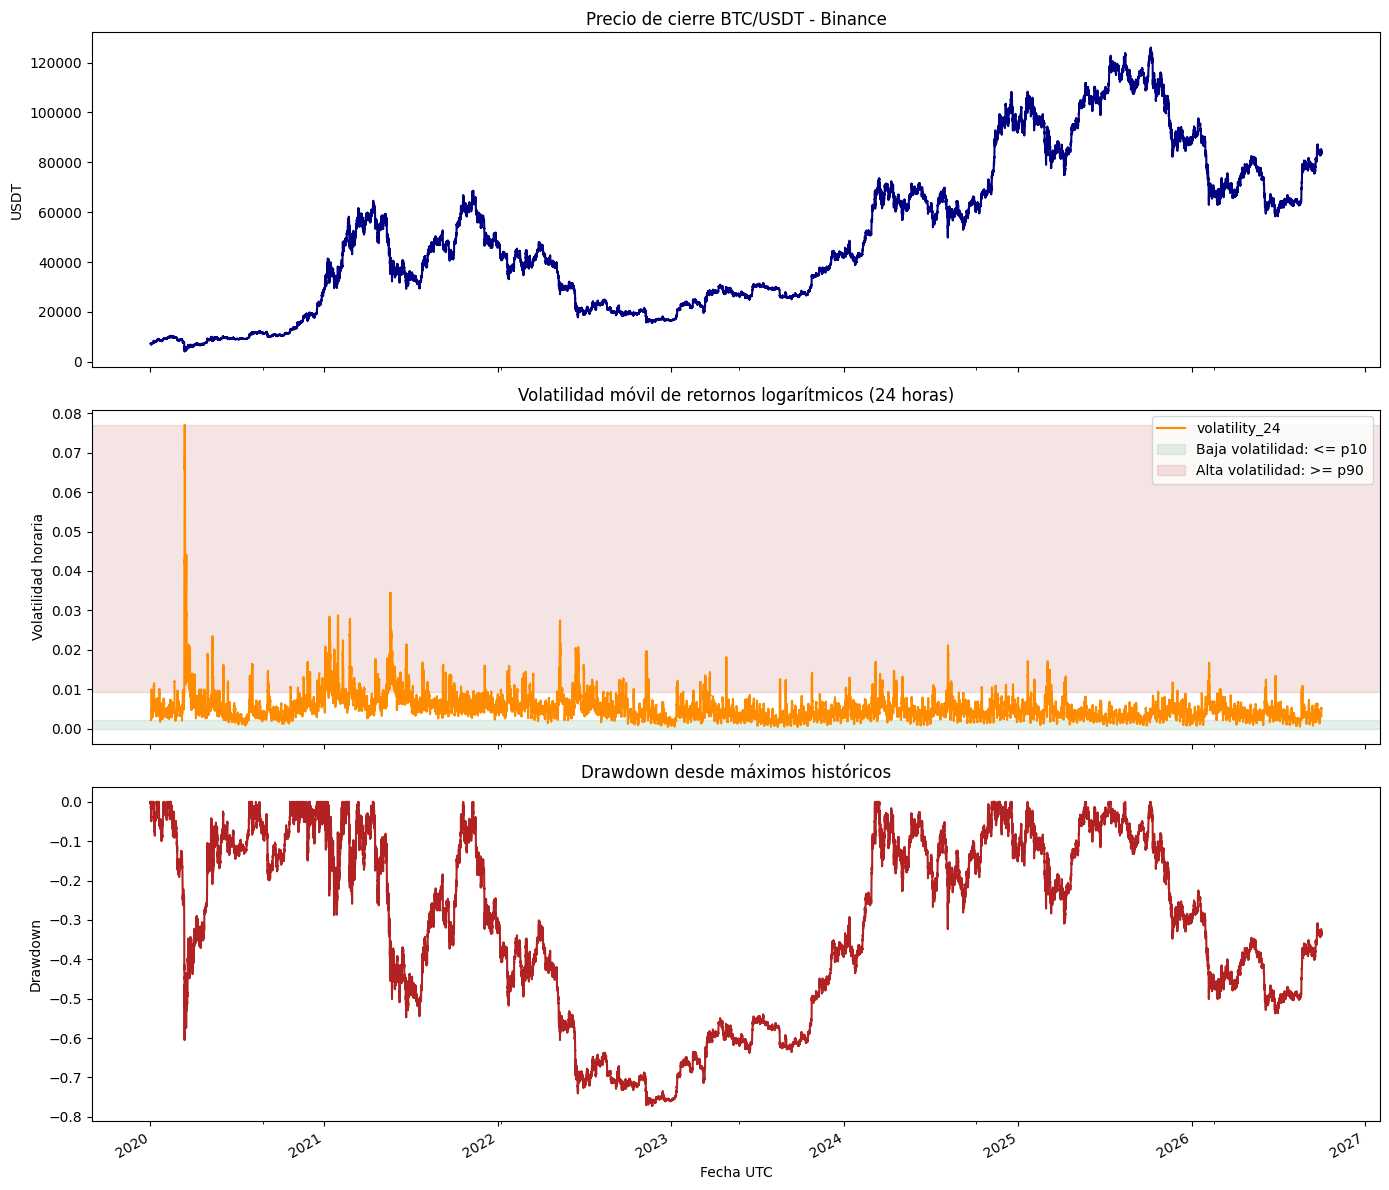

Horas de volatilidad baja (<= p10 0.002173): 5,874
Horas de volatilidad alta (>= p90 0.009226): 5,874


,timestamp,close,drawdown
25304,2022-11-21 21:00:00+00:00,15649.52,-0.771985
25313,2022-11-22 06:00:00+00:00,15687.47,-0.771432
25316,2022-11-22 09:00:00+00:00,15687.97,-0.771425
25302,2022-11-21 19:00:00+00:00,15722.98,-0.770915
25315,2022-11-22 08:00:00+00:00,15729.98,-0.770813
25305,2022-11-21 22:00:00+00:00,15740.27,-0.770663
25318,2022-11-22 11:00:00+00:00,15747.88,-0.770552
25016,2022-11-09 21:00:00+00:00,15751.13,-0.770504
25314,2022-11-22 07:00:00+00:00,15760.42,-0.770369
25306,2022-11-21 23:00:00+00:00,15781.29,-0.770065


In [15]:
valid_vol = data["volatility_24"].dropna()
low_threshold, high_threshold = valid_vol.quantile([0.10, 0.90])
fig, axes = plt.subplots(3, 1, figsize=(14, 12), sharex=True)
data.set_index("timestamp")["close"].plot(ax=axes[0], color="navy")
axes[0].set(title="Precio de cierre BTC/USDT - Binance", ylabel="USDT")
data.set_index("timestamp")["volatility_24"].plot(ax=axes[1], color="darkorange")
axes[1].axhspan(0, low_threshold, color="seagreen", alpha=0.12, label="Baja volatilidad: <= p10")
axes[1].axhspan(high_threshold, valid_vol.max(), color="firebrick", alpha=0.12, label="Alta volatilidad: >= p90")
axes[1].set(title="Volatilidad móvil de retornos logarítmicos (24 horas)", ylabel="Volatilidad horaria")
axes[1].legend(loc="upper right")
data.set_index("timestamp")["drawdown"].plot(ax=axes[2], color="firebrick")
axes[2].set(title="Drawdown desde máximos históricos", ylabel="Drawdown", xlabel="Fecha UTC")
plt.tight_layout()
plt.show()

print(f"Horas de volatilidad baja (<= p10 {low_threshold:.6f}): {(valid_vol <= low_threshold).sum():,}")
print(f"Horas de volatilidad alta (>= p90 {high_threshold:.6f}): {(valid_vol >= high_threshold).sum():,}")
data.loc[data["drawdown"].nsmallest(10).index, ["timestamp", "close", "drawdown"]]

### Análisis tendencias precio, volatilidad y caídas

1. Tendencias alcistas y bajistas

La serie de precio de cierre de BTC/USDT muestra varios ciclos claramente diferenciados durante el período analizado.

* Tendencia alcista 2020-2021

Entre 2020 y buena parte de 2021 se observa una fuerte tendencia alcista. El precio parte de niveles inferiores a 10.000 USDT y alcanza visualmente niveles cercanos o superiores a 60.000 USDT.

El movimiento no es continuo. Después del primer máximo relevante de 2021 aparece una corrección importante y posteriormente una recuperación hacia otro máximo durante ese mismo año.

Este comportamiento muestra una característica importante de Bitcoin: una tendencia global alcista puede contener correcciones internas de gran magnitud.

* Tendencia bajista 2022

Posteriormente aparece una fase claramente bajista durante 2022.

El precio desciende progresivamente desde los niveles altos alcanzados previamente hasta situarse aproximadamente en la zona de 20.000 USDT y posteriormente por debajo de esta zona.

Esta tendencia coincide visualmente con el deterioro progresivo del indicador de drawdown.

* Recuperación 2023-2025

Desde los mínimos observados alrededor de 2022-2023 se aprecia posteriormente una recuperación.

Durante 2023 el crecimiento es relativamente progresivo y a partir de 2024 la tendencia alcista se vuelve mucho más marcada. En 2025 se observan nuevos máximos históricos visualmente superiores a 120.000 USDT.

Aun dentro de esta tendencia aparecen correcciones significativas.

* Corrección 2025-2026

Después de los máximos alcanzados durante 2025, el gráfico muestra una tendencia bajista/correctiva. El precio cae desde la zona superior a 120.000 USDT hasta niveles cercanos a 60.000-70.000 USDT en algunos puntos de 2026, antes de presentar una recuperación parcial hacia el final del conjunto analizado.

Por tanto, el dataset contiene tanto mercados alcistas como bajistas y laterales, característica favorable para entrenar y evaluar un modelo bajo diferentes condiciones de mercado.

2. Episodios de caída relevantes

El gráfico de drawdown permite identificar mucho mejor las caídas que observando únicamente el precio. En la gráfica pueden distinguirse varios episodios relevantes:

* Primer episodio: 2020

Se observa una caída muy rápida que lleva el drawdown aproximadamente hacia -0.60 Destaca por su velocidad y por coincidir con el pico de volatilidad más elevado presente en la gráfica.

* Segundo episodio: 2021

Las correcciones de 2021 producen drawdowns visualmente cercanos a -0.50 a pesar de que el comportamiento global de ese período contiene importantes tendencias alcistas.

Esto resulta especialmente interesante: un mercado alcista no implica ausencia de riesgo.

* Tercer episodio: 2022-2023

Es el episodio más grave representado Drawdown cerca al -0.75 Además, tiene una recuperación relativamente lenta.

Por tanto, este episodio combina dos características negativas:

elevada profundidad;
elevada persistencia.






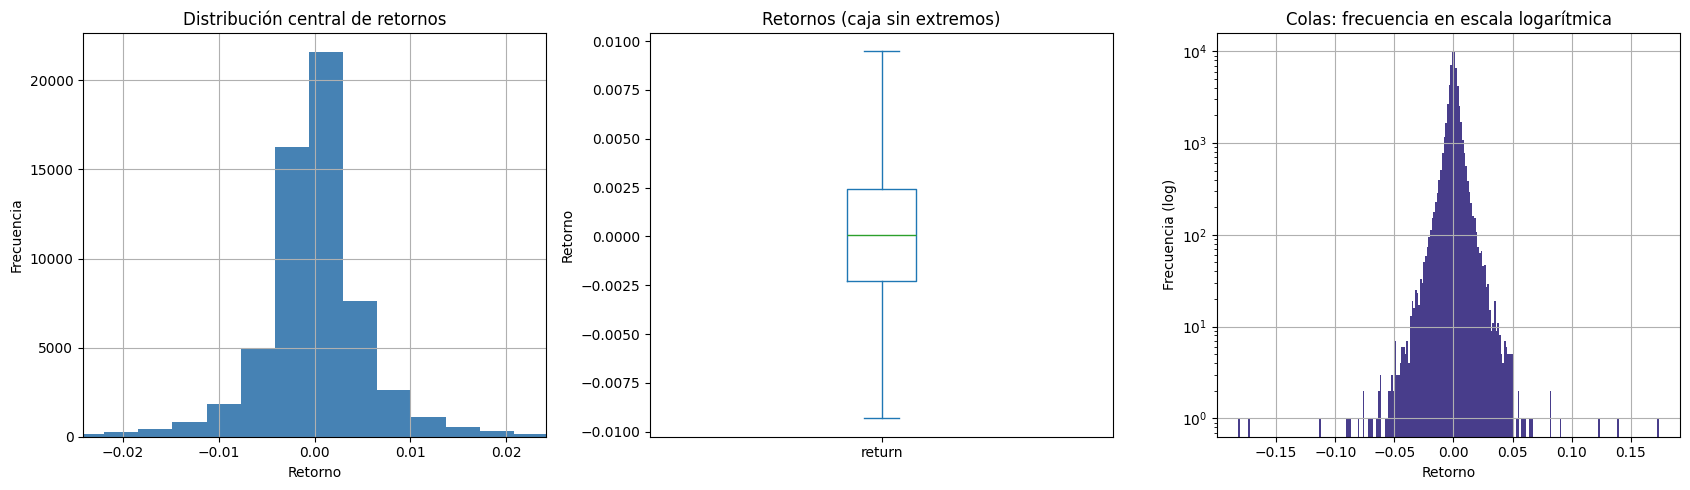

n                      59106.000000
media                      0.000062
desviacion_estandar        0.006500
asimetria                 -0.409201
curtosis_exceso           48.906479
cuantil_1_pct             -0.018873
cuantil_99_pct             0.018745
minimo                    -0.182115
maximo                     0.173840
dtype: float64

In [7]:
returns = data["return"].dropna()
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
returns.hist(bins=100, ax=axes[0], color="steelblue")
axes[0].set(title="Distribución central de retornos", xlabel="Retorno", ylabel="Frecuencia")
axes[0].set_xlim(returns.quantile(0.005), returns.quantile(0.995))
returns.plot.box(ax=axes[1], showfliers=False)
axes[1].set(title="Retornos (caja sin extremos)", ylabel="Retorno")
returns.hist(bins=250, ax=axes[2], color="darkslateblue")
axes[2].set_yscale("log")
axes[2].set(title="Colas: frecuencia en escala logarítmica", xlabel="Retorno", ylabel="Frecuencia (log)")
plt.tight_layout()
plt.show()

return_summary = pd.Series({
    "n": returns.size,
    "media": returns.mean(),
    "desviacion_estandar": returns.std(),
    "asimetria": returns.skew(),
    "curtosis_exceso": returns.kurt(),
    "cuantil_1_pct": returns.quantile(0.01),
    "cuantil_99_pct": returns.quantile(0.99),
    "minimo": returns.min(),
    "maximo": returns.max(),
})
return_summary

### Distribución de retornos

Análisis de la distribución de retornos

La distribución de los retornos horarios de BTC/USDT se encuentra fuertemente concentrada alrededor de cero. Para las 59.106 observaciones analizadas se obtuvo un retorno medio de 0,000062, equivalente aproximadamente a 0,0062 % por hora, y una desviación estándar de 0,0065, equivalente aproximadamente a 0,65 %. Estos resultados indican que el retorno promedio por observación es reducido en comparación con la variabilidad presentada por la serie.

La distribución presenta una asimetría de -0,4092, indicando una ligera inclinación hacia la cola negativa. Asimismo, se obtuvo una curtosis en exceso de 48,9065, valor considerablemente superior al valor de cero correspondiente a una distribución normal. Este resultado evidencia un comportamiento leptocúrtico, caracterizado por una elevada concentración de observaciones alrededor del centro y la presencia de colas pesadas con eventos extremos.

El análisis de los percentiles confirma este comportamiento. El percentil 1 % corresponde a un retorno de aproximadamente -1,8873 %, mientras que el percentil 99 % corresponde aproximadamente a +1,8745 %. Por lo tanto, alrededor del 98 % central de las observaciones se encuentra comprendido entre estos dos valores. Sin embargo, el retorno mínimo observado alcanza -18,2115 % y el máximo +17,3840 %, valores considerablemente más extremos que los límites definidos por los percentiles 1 % y 99 %. En términos de magnitud, el mínimo observado es aproximadamente 9,65 veces el umbral del percentil 1 %, mientras que el máximo es aproximadamente 9,27 veces el percentil 99 %.

La forma observada difiere notablemente de una distribución normal. Mientras que una distribución normal presenta asimetría cercana a cero y curtosis en exceso cercana a cero, los retornos analizados presentan asimetría negativa y, especialmente, una curtosis en exceso muy elevada. Esto indica que un modelo que suponga normalidad podría representar inadecuadamente la probabilidad de movimientos extremos del mercado.

La presencia de colas pesadas resulta especialmente relevante para el posterior diseño de un agente de aprendizaje por refuerzo. Una función de recompensa basada exclusivamente en el retorno podría favorecer estrategias rentables en promedio sin representar adecuadamente la exposición a pérdidas extremas. Los resultados obtenidos justifican estudiar funciones de recompensa ajustadas por riesgo, incorporando variables como volatilidad o drawdown, y evaluar experimentalmente si estas producen políticas más robustas.


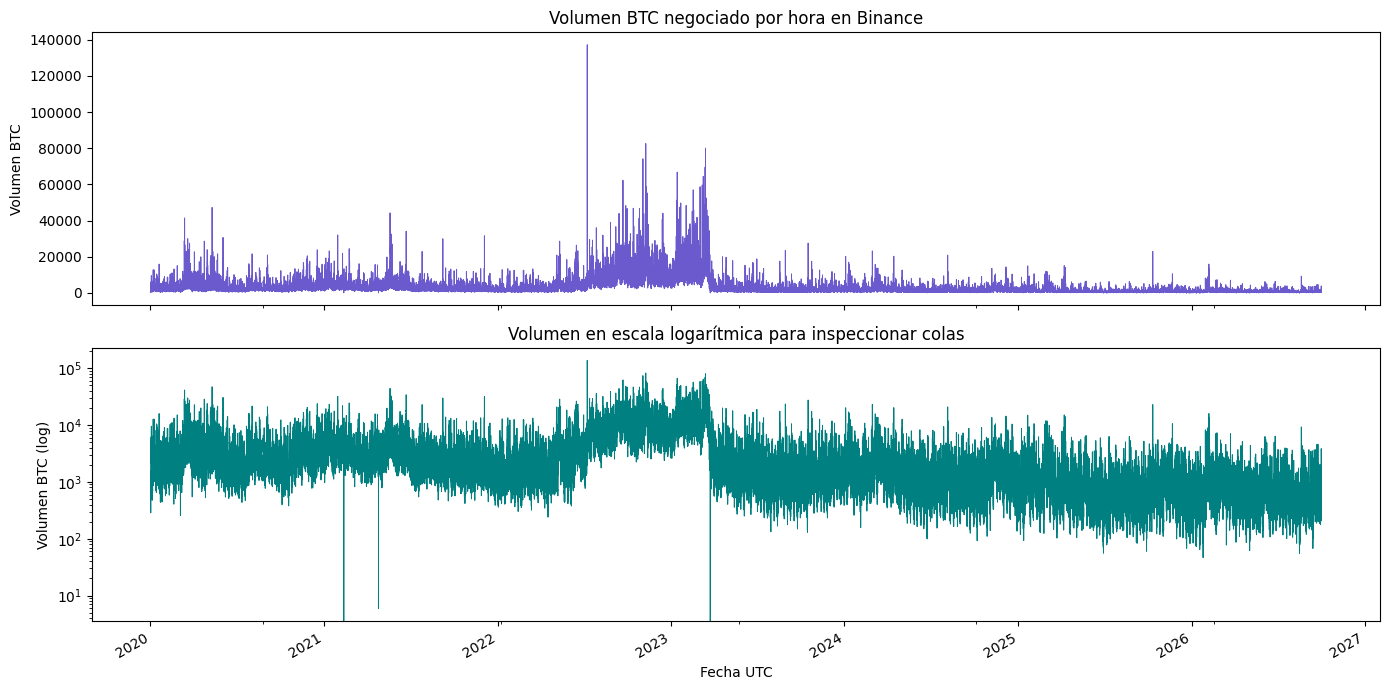

count     59122.000000
mean       2823.906922
std        4269.598315
min           0.000000
50%        1449.475307
90%        6595.448239
99%       21135.573026
max      137207.188600
Name: volume, dtype: float64

In [8]:
fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
data.set_index("timestamp")["volume"].plot(ax=axes[0], color="slateblue", linewidth=0.7)
axes[0].set(title="Volumen BTC negociado por hora en Binance", ylabel="Volumen BTC")
data.set_index("timestamp")["volume"].plot(ax=axes[1], color="teal", linewidth=0.7)
axes[1].set_yscale("log")
axes[1].set(title="Volumen en escala logarítmica para inspeccionar colas", ylabel="Volumen BTC (log)", xlabel="Fecha UTC")
plt.tight_layout()
plt.show()
data["volume"].describe(percentiles=[0.5, 0.9, 0.99])

### Análisis de volumen

El volumen presenta asimetría positiva pronunciada, cambios de régimen y una cola superior con observaciones extremas. Por ello, utilizar únicamente el volumen bruto puede dificultar el modelado. La transformación log1p(volume) constituye una característica candidata razonable, mientras que la relación entre volumen, volatilidad y retorno absoluto debe evaluarse como parte de la ingeniería de características antes del entrenamiento del agente.

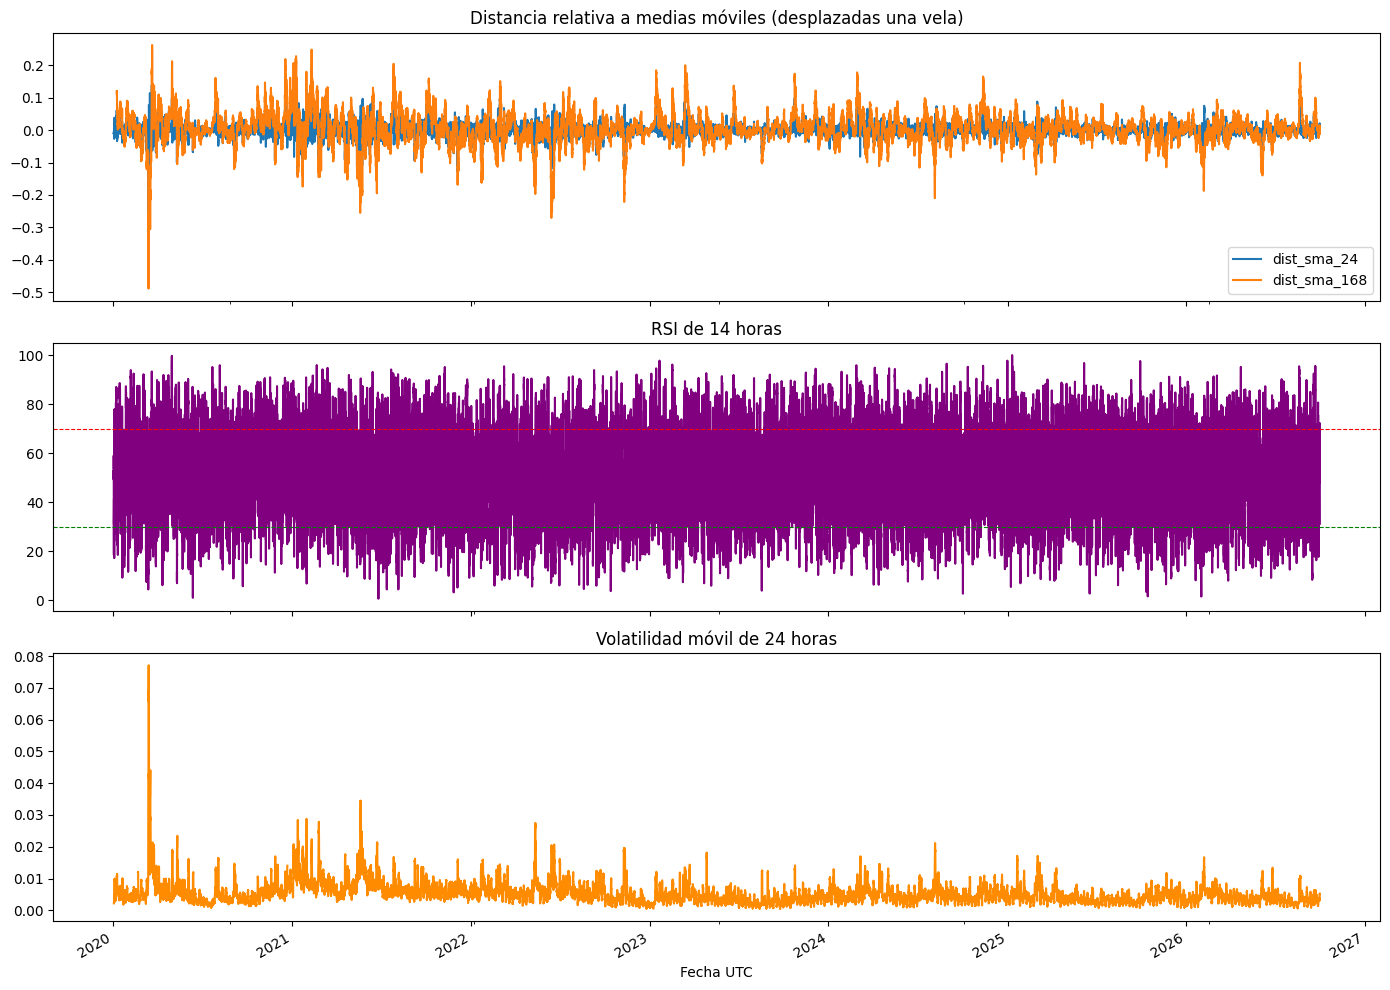

In [16]:
fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)
data.set_index("timestamp")[["dist_sma_24", "dist_sma_168"]].plot(ax=axes[0])
axes[0].set_title("Distancia relativa a medias móviles (desplazadas una vela)")
data.set_index("timestamp")["rsi_14"].plot(ax=axes[1], color="purple")
axes[1].axhline(70, color="red", linestyle="--", linewidth=0.8)
axes[1].axhline(30, color="green", linestyle="--", linewidth=0.8)
axes[1].set_title("RSI de 14 horas")
data.set_index("timestamp")["volatility_24"].plot(ax=axes[2], color="darkorange")
axes[2].set_title("Volatilidad móvil de 24 horas")
axes[-1].set_xlabel("Fecha UTC")
plt.tight_layout()
plt.show()

### Indicadores de mercado

El análisis de las distancias relativas respecto de las medias móviles de 24 y 168 horas permite evaluar la posición del precio respecto de sus tendencias recientes. Los valores positivos representan precios superiores a la media móvil correspondiente, mientras que los valores negativos indican que el precio se encuentra por debajo de dicha referencia. La mayor parte de las observaciones se concentra visualmente alrededor de cero, aunque se presentan episodios de desviaciones considerablemente mayores. Destaca particularmente un episodio al comienzo de 2020 en el que la distancia respecto de la referencia de 168 horas alcanza visualmente valores negativos cercanos a -0,50, evidenciando un fuerte alejamiento del precio respecto de su tendencia semanal previa.

Las ventanas de 24 y 168 observaciones representan horizontes complementarios. Debido a que el dataset presenta frecuencia horaria, la primera corresponde aproximadamente a un día y la segunda a una semana. La ventana de 24 horas responde más rápidamente a los movimientos recientes, mientras que la de 168 horas proporciona una referencia más lenta de la tendencia. Las distancias relativas permiten además expresar estos movimientos independientemente del nivel absoluto de cotización de BTC, lo que resulta relevante en un conjunto de datos que abarca períodos con niveles de precio considerablemente diferentes.

El RSI calculado sobre 14 observaciones representa el momentum de corto plazo. La gráfica muestra frecuentes desplazamientos del indicador a través de los niveles de referencia 30 y 70, así como períodos en los que el RSI permanece en regiones relativamente elevadas o reducidas durante múltiples observaciones. Por esta razón, los niveles 30 y 70 no deben interpretarse de manera determinística como señales inmediatas de compra o venta. En el contexto del modelo, resulta más apropiado utilizar el RSI como una variable descriptiva del estado del mercado y permitir que el procedimiento de aprendizaje determine la utilidad predictiva de los diferentes niveles del indicador.

La volatilidad móvil de 24 horas presenta importantes variaciones a través del tiempo. Se observan períodos relativamente estables alternados con episodios de elevada volatilidad, comportamiento consistente con la existencia de diferentes regímenes de mercado. Destaca nuevamente el episodio observado a comienzos de 2020, donde la volatilidad alcanza visualmente valores extraordinariamente superiores a su nivel habitual. Este período coincide además con grandes desviaciones del precio respecto de sus medias móviles y con el episodio de fuerte drawdown identificado previamente.

En conjunto, los indicadores proporcionan información complementaria. Las distancias relativas respecto de las medias móviles describen la posición del precio frente a sus tendencias recientes; el RSI caracteriza el momentum; y la volatilidad móvil representa la intensidad y dispersión reciente de los movimientos. Una combinación de estos indicadores permite construir una representación del estado del mercado más completa que aquella basada exclusivamente en el precio o retorno.

No obstante, debido a que varias de estas variables son transformaciones derivadas del mismo precio de cierre, deberá evaluarse posteriormente la existencia de redundancia entre características. La incorporación de una mayor cantidad de indicadores no garantiza automáticamente un mejor desempeño predictivo; su utilidad deberá comprobarse mediante validación temporal y mediante comparación del desempeño fuera de muestra.

In [10]:
split_config = load_split_config(CONFIG_PATH)
train_end = pd.Timestamp(split_config["train_end_exclusive"])
validation_end = pd.Timestamp(split_config["validation_end_exclusive"])
held_out_end = pd.Timestamp(split_config["held_out_end_exclusive"])
partitions = split_by_dates(data, split_config)
total_partition_rows = sum(len(part) for part in partitions.values())
train_fraction = len(partitions["train"]) / total_partition_rows
assert train_fraction >= 0.70, f"Entrenamiento representa solo {train_fraction:.2%} de las filas"
assert validation_end >= train_end + pd.DateOffset(years=1)
assert held_out_end >= validation_end + pd.DateOffset(years=1)
print(f"Porcentaje de filas de entrenamiento: {train_fraction:.2%}")
print(f"Fechas de corte UTC: train<{train_end}; validation<{validation_end}; held-out<{held_out_end}")
period_rows = []
for name, part in partitions.items():
    part = part.sort_values("timestamp")
    period_returns = np.log(part["close"]).diff().where(part["timestamp"].diff().eq(frequency)).dropna()
    log_prices = np.log(part["close"].to_numpy(dtype=float))
    elapsed_hours = (part["timestamp"] - part["timestamp"].iloc[0]).dt.total_seconds().to_numpy() / 3600
    slope = np.polyfit(elapsed_hours, log_prices, 1)[0] if len(log_prices) > 1 else np.nan
    period_rows.append({
        "periodo": name,
        "observaciones": len(part),
        "porcentaje_muestras": len(part) / total_partition_rows,
        "retorno_log_medio_horario": period_returns.mean(),
        "volatilidad_log_horaria": period_returns.std(),
        "volatilidad_anualizada": period_returns.std() * np.sqrt(24 * 365.25),
        "tendencia_log_anualizada_aprox": np.expm1(slope * 24 * 365.25),
        "max_drawdown": (part["close"] / part["close"].cummax() - 1).min(),
    })
period_comparison = pd.DataFrame(period_rows).set_index("periodo")
period_comparison

Porcentaje de filas de entrenamiento: 70.37%
Fechas de corte UTC: train<2024-10-01 00:00:00+00:00; validation<2025-10-01 00:00:00+00:00; held-out<2026-10-01 00:00:00+00:00


,observaciones,porcentaje_muestras,retorno_log_medio_horario,volatilidad_log_horaria,volatilidad_anualizada,tendencia_log_anualizada_aprox,max_drawdown
periodo,,,,,,,
train,41602,0.703664,0.000051,0.007118,0.666450,0.338217,-0.771985
validation,8760,0.148168,0.000067,0.004885,0.457371,0.550208,-0.309361
held_out,8760,0.148168,-0.000036,0.004691,0.439204,-0.359755,-0.537421


### Particiones y no-estacionariedad

El conjunto de datos fue dividido cronológicamente en tres particiones. El conjunto de entrenamiento contiene 41.602 observaciones, equivalentes al 70,37 % de las muestras; validation y held-out contienen 8.760 observaciones cada uno, correspondientes aproximadamente al 14,82 % de las muestras respectivamente. La división conserva estrictamente el orden temporal, asignando las observaciones anteriores al 1 de octubre de 2024 al entrenamiento, el período comprendido entre octubre de 2024 y septiembre de 2025 a validación y el período entre octubre de 2025 y septiembre de 2026 al conjunto held-out.

La comparación de los estadísticos evidencia diferencias importantes entre las particiones. El retorno logarítmico medio horario es positivo tanto en entrenamiento (0,000051) como en validación (0,000067), mientras que en held-out cambia de signo y alcanza -0,000036. Un comportamiento similar se observa en la tendencia logarítmica anualizada aproximada, que pasa de 0,3382 en entrenamiento y 0,5502 en validación a -0,3598 en held-out. Este cambio indica que el conjunto final de evaluación representa un entorno direccional considerablemente diferente de los períodos utilizados durante el desarrollo del agente.

También se identifican diferencias en la volatilidad. El conjunto de entrenamiento presenta una volatilidad logarítmica horaria de 0,007118 y una volatilidad anualizada de aproximadamente 66,65 %, superiores a las obtenidas en validación, con aproximadamente 45,74 % anualizado, y held-out, con aproximadamente 43,92 %. Validation y held-out presentan niveles de volatilidad relativamente similares, pero tendencias de signo opuesto, demostrando que un nivel semejante de volatilidad no implica condiciones direccionales equivalentes.

Las diferencias también son evidentes en el máximo drawdown. El conjunto de entrenamiento contiene la caída histórica más severa, con un drawdown máximo aproximado de -77,20 %. Validation presenta un máximo drawdown considerablemente menor, de aproximadamente -30,94 %, mientras que held-out vuelve a presentar una pérdida desde máximos significativa, cercana a -53,74 %. En consecuencia, validation representa un período comparativamente favorable en términos de tendencia y drawdown, mientras que held-out combina una tendencia negativa con pérdidas desde máximos considerablemente superiores.

En conjunto, estos resultados proporcionan evidencia de que las propiedades estadísticas del mercado no permanecen constantes entre las diferentes particiones. Las diferencias en retorno medio, tendencia, volatilidad y drawdown sugieren la presencia de cambios de régimen y dificultan asumir que los resultados obtenidos durante entrenamiento se reproducirán directamente en períodos posteriores.

Esta característica constituye además una prueba relevante para la capacidad de generalización del agente de aprendizaje por refuerzo. Un agente que dependa excesivamente de patrones asociados con mercados predominantemente alcistas podría obtener resultados satisfactorios en entrenamiento y validación, pero deteriorar significativamente su desempeño durante el período held-out, cuya tendencia media es negativa. Por ello, el desempeño final debe evaluarse considerando tanto rentabilidad como riesgo y comparándolo con estrategias de referencia.

Finalmente, el conjunto held-out debe mantenerse completamente aislado durante la selección de variables, el ajuste de hiperparámetros, la definición de la función de recompensa y cualquier otra decisión de diseño. Utilizar sus resultados para modificar posteriormente el agente introduciría sesgo en la evaluación final y convertiría al held-out, en la práctica, en un segundo conjunto de validación